In [18]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [6]:
df=pd.read_excel(r"C:\Users\ELCOT\Desktop\Sowmiga\Python Workspace\Milestone Project\Intelligent_Ticket_Classification_Dataset.xlsx")

In [7]:
df.head()

,Ticket_ID,Created_At,Channel,Customer_Type,Customer_Tenure_Months,Previous_Ticket_Count,Product_or_Service,Operating_System,Business_Impact,Affected_Users_Count,...,Response_Template_ID,SLA_Target_Hours,SLA_Breached,Customer_Satisfaction_Score,Ticket_Status,Predicted_Category_Target,Automation_Eligibility,Recommended_Routing,Recommended_Action,Approved_Response_Template_ID
0,TKT-000001,2026-08-25 23:39:00,Email,Internal Employee,78,3,Knowledge portal,Android,Medium,5,...,RSP-044,8,No,1.0,Closed,General Information,AUTO_RESOLVABLE,SELF_SERVICE,SEND_APPROVED_RESPONSE,RSP-044
1,TKT-000002,2025-12-06 00:51:00,Email,Individual,136,5,Customer billing portal,Android,Low,1,...,RSP-025,24,Yes,NaN,Resolved,Billing and Payments,AGENT_REQUIRED,BILLING_TEAM,ESCALATE_TO_SPECIALIST,Not Applicable
2,TKT-000003,2026-09-01 05:46:00,Email,Internal Employee,71,4,VPN account,Android,Medium,10,...,RSP-002,24,No,NaN,Closed,Account Access,AGENT_REQUIRED,L1_SUPPORT,ASSIGN_TO_AGENT,Not Applicable
3,TKT-000004,2026-03-18 22:02:00,Live Chat,Enterprise,155,3,Equipment request,Unknown,Low,1,...,RSP-031,72,No,1.0,In Progress,Orders and Service Requests,AGENT_REQUIRED,CUSTOMER_OPERATIONS,ESCALATE_TO_SPECIALIST,Not Applicable
4,TKT-000005,2026-04-30 10:06:00,Email,Individual,57,2,Service desk portal,iOS,High,2,...,RSP-042,8,Yes,1.0,Resolved,General Information,AGENT_REQUIRED,SELF_SERVICE,ESCALATE_TO_SPECIALIST,Not Applicable


In [8]:
df.sample(5)

,Ticket_ID,Created_At,Channel,Customer_Type,Customer_Tenure_Months,Previous_Ticket_Count,Product_or_Service,Operating_System,Business_Impact,Affected_Users_Count,...,Response_Template_ID,SLA_Target_Hours,SLA_Breached,Customer_Satisfaction_Score,Ticket_Status,Predicted_Category_Target,Automation_Eligibility,Recommended_Routing,Recommended_Action,Approved_Response_Template_ID
11802,TKT-011803,2026-01-17 23:11:00,Phone,Small Business,168,5,Knowledge portal,Not Applicable,Medium,25,...,RSP-043,24,No,4.0,Escalated,General Information,AUTO_RESOLVABLE,SELF_SERVICE,SUGGEST_KNOWLEDGE_BASE_ARTICLE,RSP-043
3273,TKT-003274,2026-09-20 23:02:00,Live Chat,Enterprise,70,0,Laptop,macOS,High,3,...,RSP-018,8,No,NaN,Escalated,Hardware,AGENT_REQUIRED,HARDWARE_SUPPORT,ESCALATE_TO_SPECIALIST,Not Applicable
9173,TKT-009174,2026-01-01 14:28:00,Live Chat,Enterprise,5,2,Subscription account,Android,High,3,...,RSP-026,8,No,3.0,Escalated,Billing and Payments,AGENT_REQUIRED,BILLING_TEAM,REQUEST_MORE_INFORMATION,Not Applicable
1015,TKT-001016,2025-11-18 06:15:00,Email,Small Business,3,1,Team collaboration app,Android,Medium,25,...,RSP-015,24,No,NaN,Escalated,Email and Collaboration,AGENT_REQUIRED,L1_SUPPORT,ASSIGN_TO_AGENT,Not Applicable
5548,TKT-005549,2026-03-20 03:02:00,Mobile App,Individual,31,4,Customer portal,iOS,Medium,50,...,Not Applicable,8,Yes,2.0,Resolved,General Information,AGENT_REQUIRED,SELF_SERVICE,REQUEST_MORE_INFORMATION,Not Applicable


Tickets sheet contains 12,000 rows and 42 columns.

In [9]:
df.shape

(12000, 42)

In [10]:
print(df.duplicated().sum())

0


In [11]:
print(df["Ticket_ID"].duplicated().sum())

0


In [12]:
df.isnull().sum()

Ticket_ID                                 0
Created_At                                0
Channel                                   0
Customer_Type                             0
Customer_Tenure_Months                    0
Previous_Ticket_Count                     0
Product_or_Service                        0
Operating_System                          0
Business_Impact                           0
Affected_Users_Count                      0
Ticket_Subject                            0
Ticket_Description                        0
Customer_Reported_Error                 762
Customer_Sentiment                        0
Language                                  0
Previous_Troubleshooting_Attempts         0
Actual_Category                           0
Actual_Subcategory                        0
Actual_Assigned_Department                0
Actual_Priority                           0
Actual_Assigned_Team                      0
Actual_Assigned_Agent_ID                  0
Classification_Confidence_Refere

In [ ]:
missing = df.isnull().sum()

print(missing[missing > 0])

Customer_Reported_Error         762
Customer_Satisfaction_Score    3401
dtype: int64


In [20]:
df["Customer_Reported_Error"] = df["Customer_Reported_Error"].fillna("Unknown")

In [21]:
df["Customer_Satisfaction_Score"].describe()

count    12000.000000
mean         2.730667
std          1.167793
min          1.000000
25%          2.000000
50%          3.000000
75%          3.000000
max          5.000000
Name: Customer_Satisfaction_Score, dtype: float64

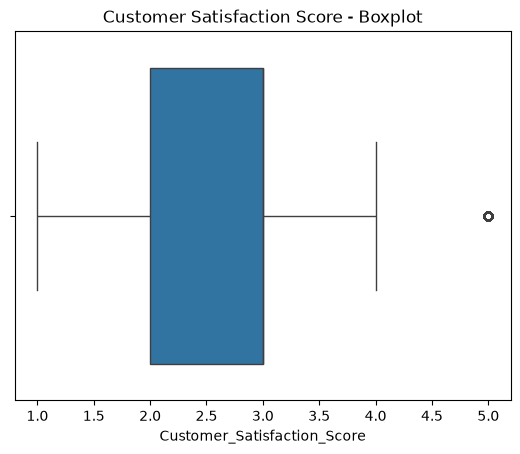

In [22]:
sns.boxplot(x=df["Customer_Satisfaction_Score"])
plt.title("Customer Satisfaction Score - Boxplot")
plt.show()

In [23]:
score = df["Customer_Satisfaction_Score"]

print("Mean:", score.mean())
print("Median:", score.median())
print("Skewness:", score.skew())

Mean: 2.7306666666666666
Median: 3.0
Skewness: 0.024189802047111603


In [25]:
df["Customer_Satisfaction_Score"].fillna(df["Customer_Satisfaction_Score"].median(), inplace=True)

C:\Users\ELCOT\AppData\Local\Temp\ipykernel_4684\416966658.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df["Customer_Satisfaction_Score"].fillna(df["Customer_Satisfaction_Score"].median(), inplace=True)


0        1.0
1        3.0
2        3.0
3        1.0
4        1.0
        ... 
11995    3.0
11996    3.0
11997    2.0
11998    3.0
11999    1.0
Name: Customer_Satisfaction_Score, Length: 12000, dtype: float64

Encoding


In [26]:
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Categorical Columns:", categorical_cols)
print("Numerical Columns:", numerical_cols)

Categorical Columns: ['Ticket_ID', 'Created_At', 'Channel', 'Customer_Type', 'Product_or_Service', 'Operating_System', 'Business_Impact', 'Ticket_Subject', 'Ticket_Description', 'Customer_Reported_Error', 'Customer_Sentiment', 'Language', 'Previous_Troubleshooting_Attempts', 'Actual_Category', 'Actual_Subcategory', 'Actual_Assigned_Department', 'Actual_Priority', 'Actual_Assigned_Team', 'Actual_Assigned_Agent_ID', 'Resolved_On_First_Contact', 'Reopened', 'Escalated', 'Escalation_Reason', 'Resolution_Type', 'Resolution_Summary', 'Knowledge_Base_Article_ID', 'Response_Template_ID', 'SLA_Breached', 'Ticket_Status', 'Predicted_Category_Target', 'Automation_Eligibility', 'Recommended_Routing', 'Recommended_Action', 'Approved_Response_Template_ID']
Numerical Columns: ['Customer_Tenure_Months', 'Previous_Ticket_Count', 'Affected_Users_Count', 'Classification_Confidence_Reference', 'First_Response_Time_Minutes', 'Resolution_Time_Hours', 'SLA_Target_Hours', 'Customer_Satisfaction_Score']


C:\Users\ELCOT\AppData\Local\Temp\ipykernel_4684\681933711.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()


In [31]:
encoding_cols = [
    "Channel",
    "Customer_Type",
    "Product_or_Service",
    "Operating_System",
    "Business_Impact",
    "Customer_Sentiment",
    "Language"
]

print(df[encoding_cols].head())

     Channel      Customer_Type       Product_or_Service Operating_System  \
0      Email  Internal Employee         Knowledge portal          Android   
1      Email         Individual  Customer billing portal          Android   
2      Email  Internal Employee              VPN account          Android   
3  Live Chat         Enterprise        Equipment request          Unknown   
4      Email         Individual      Service desk portal              iOS   

  Business_Impact Customer_Sentiment            Language  
0          Medium           Negative             English  
1             Low         Frustrated             English  
2          Medium           Negative             English  
3             Low            Neutral  English (informal)  
4            High            Neutral             English  


In [32]:
df_encoded = pd.get_dummies(df, columns=encoding_cols, dtype=int)
print(df_encoded.head())

    Ticket_ID           Created_At  Customer_Tenure_Months  \
0  TKT-000001  2026-08-25 23:39:00                      78   
1  TKT-000002  2025-12-06 00:51:00                     136   
2  TKT-000003  2026-09-01 05:46:00                      71   
3  TKT-000004  2026-03-18 22:02:00                     155   
4  TKT-000005  2026-04-30 10:06:00                      57   

   Previous_Ticket_Count  Affected_Users_Count  \
0                      3                     5   
1                      5                     1   
2                      4                    10   
3                      3                     1   
4                      2                     2   

                          Ticket_Subject  \
0  Documentation Request: issue reported   
1       Incorrect Charge: issue reported   
2              Account Lockout: question   
3      Cancellation: request for support   
4    Product Information: issue reported   

                                  Ticket_Description Customer

In [35]:
print(df_encoded.shape)

(12000, 105)
